# Ein Neuron ausprobieren
**Doppellektion 3 · Experimentier-Notebook.** Ein künstliches Neuron verrechnet Eingaben mit Gewichten und einem Bias. Ist die Summe mindestens 0, gibt es 1 aus, sonst 0. Hier verändern Sie diese Werte, beobachten das Lernen und untersuchen XOR. **Pflicht:** Alltagsregler, Rechenbeispiel, Lernversuch und XOR; weiteres ist Vertiefung.


**So arbeiten Sie:** Erst vermuten, dann das Ergebnis ansehen; pro Versuch nur eine Einstellung ändern. Startzellen laufen automatisch (Status oben). Regler und Knöpfe bedienen Sie direkt; wenn Sie Code ändern, starten Sie die Zelle mit **Shift + Enter**. Unter den Selbstchecks klicken Sie eine Antwort an und bekommen sofort eine Rückmeldung. Ihre Einstellungen und Ergebnisse (Gewichte, Bias, Runden, Treffer) tragen Sie ins **Protokoll** der Kursseite ein (Kapitel «Im Notebook»), Erklärungen ins Antwortfeld der Kursseite oder aufs Arbeitsblatt.

In [ ]:
# Startet in JupyterLite automatisch. Bei Bedarf mit Shift + Enter erneut ausführen.
import sys
if sys.platform == 'emscripten':
    import pyodide_js
    await pyodide_js.loadPackage(['numpy', 'scipy', 'scikit-learn', 'matplotlib', 'pillow'])
    try:
        import ipywidgets
    except ImportError:
        import piplite
        await piplite.install('ipywidgets==8.1.0')
import unterricht_tools as u
print('Bereit. Einstellungen ändern und die betreffende Zelle mit Shift + Enter ausführen.')

## Experiment · Einfluss der Eingaben
Beim Alltagsbeispiel: Verändern Sie **nur das Gewicht der Prüfung**. In welcher Situation kippt die Entscheidung?


In [ ]:
u.regler_alltag();

In [ ]:
u.frage('Was macht ein künstliches Neuron?',
    ['Es speichert alle Beispiele auswendig',
     'Es rechnet aus mehreren Zahlen eine gewichtete Summe und gibt Ja (1) oder Nein (0) aus',
     'Es schreibt Wenn-dann-Regeln auf',
     'Es sucht die Antwort im Internet'],
    richtig=1,
    erklaerung='Eingaben mal Gewichte, plus Bias, dann ab 0 «Ja»: Das ist die ganze Aufgabe eines Neurons.');

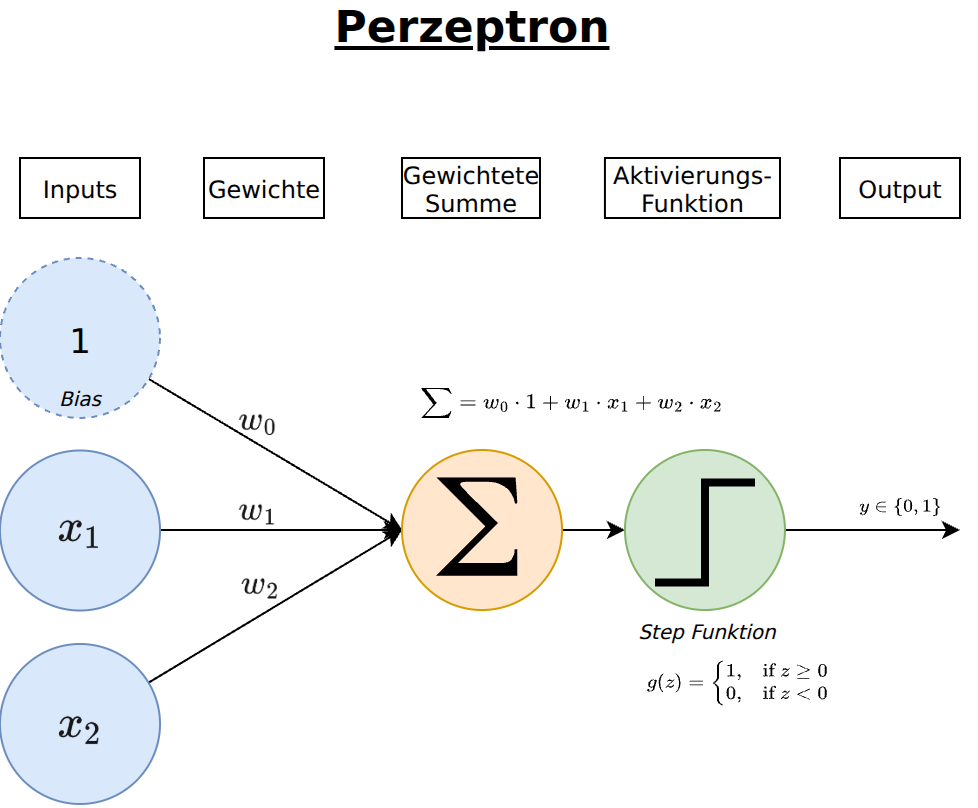

*Lesen Sie von links nach rechts. Die feste Eingabe 1 trägt den Bias bei: ihr Gewicht ist der Bias.*

## Transfer · Vom Vorbild zur Rechenregel
Vergleichen Sie die Grafik mit dem Schema der Kursseite: Wo werden Eingaben gewichtet, wo entscheidet die Schwelle?


## Freiwilliger Zusatz · Biologie
Vergleichen Sie das künstliche Neuron mit der biologischen Nervenzelle. Was wird stark vereinfacht?

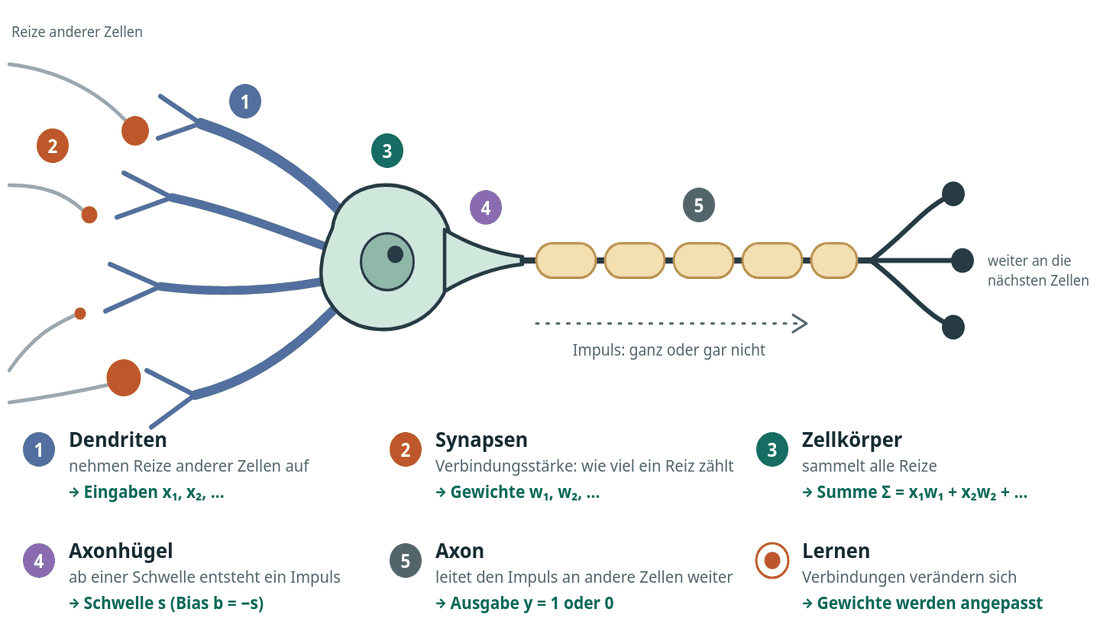


In [ ]:
u.neuron_vergleich()

## Experiment · Mit Zahlen entscheiden
Ändern Sie eine Eingabe oder ein Gewicht. Vergleichen Sie Summe und Ausgabe vor und nach der Änderung.


In [ ]:
u.neuron_rechner();

In [ ]:
u.frage('Gewichte 1 und 1, Bias −1.5, Eingabe (1, 0): Was gibt das Neuron aus?',
    ['Ausgabe 1, weil die Summe der Eingaben 1 beträgt',
     'Ausgabe 0, weil 1 + (−1.5) = −0.5 kleiner als 0 ist',
     'Ausgabe −0.5'],
    richtig=1,
    erklaerung='Die Summe 1·1 + 0·1 + (−1.5) = −0.5 liegt unter 0: Das Neuron feuert nicht. Die Ausgabe ist immer 0 oder 1.');

## Experiment · AND selbst einstellen
**AND** gibt nur dann 1 aus, wenn **beide** Eingaben 1 sind. Wählen Sie Gewichte und Bias so, dass die Ausgaben für `(0,0)`, `(0,1)`, `(1,0)` und `(1,1)` stimmen. Bei **OR** reicht eine aktive Eingabe; bei **NAND** ist nur `(1,1)` gleich 0. Prüfen Sie die Wahrheitstabelle im Regler.


In [ ]:
u.regler_perzeptron();

## Experiment · Lernen beobachten
Das Netz erhält für jede Eingabe ein Ziel. Weicht die Ausgabe davon ab, werden Gewichte und Bias korrigiert. Verfolgen Sie **einen** falschen Fall: Welche Zahl ändert sich und wie wirkt sich das auf die nächste Vorhersage aus?


In [ ]:
u.lernen_klick();

### Lernen über mehrere Runden
Wie viele Korrekturen sind nötig? Vergleichen Sie die Werte vor und nach dem Lernen.


In [ ]:
u.lernen_regler();

In [ ]:
u.frage('Was verändert sich, wenn ein Neuron lernt?',
    ['Die Eingaben', 'Die Gewichte und der Bias', 'Die Rechenregel «Summe bilden, ab 0 feuern»', 'Die Zielwerte'],
    richtig=1,
    erklaerung='Nur Gewichte und Bias werden angepasst. Sie sind der Erfahrungsschatz des Neurons; die Rechenregel bleibt gleich.');

## Transfer · Pflanzen erkennen
Testen Sie eine Pflanze nahe der Entscheidungsgrenze. Weshalb könnte ihre Zuordnung unsicher sein?


In [ ]:
u.iris_regler();

## Problem · XOR
**XOR** gibt 1 aus, wenn **genau eine** Eingabe 1 ist: `(0,1)` und `(1,0)` sind 1, `(0,0)` und `(1,1)` sind 0. Lassen Sie das Neuron trainieren und prüfen Sie, ob alle vier Fälle richtig werden.


In [ ]:
w, b = u.perzeptron_lernen('XOR', runden=8)

**Beobachten:** Welche Punkte müssten gemeinsam auf einer Seite der Entscheidungsgrenze liegen?


In [ ]:
u.xor_problem()

**Versuchen:** Stellen Sie die Regler um. Können alle vier Fälle gleichzeitig stimmen?


In [ ]:
u.regler_xor();

**Vertiefung:** Untersuchen Sie die Bedingungen an Gewichte und Bias. Weshalb ist keine einzelne Gerade ausreichend?


In [ ]:
u.xor_suche()

In [ ]:
u.frage('Warum kann ein einzelnes Neuron XOR nicht lösen?',
    ['Es hat zu wenige Trainingsrunden',
     'Die Lernrate war falsch gewählt',
     'Seine Grenze ist eine gerade Linie, und die beiden Klassen liegen diagonal gegenüber',
     'XOR ist für Computer zu schwer'],
    richtig=2,
    erklaerung='Eine Gerade kann die Punkte (0, 1) und (1, 0) nicht von (0, 0) und (1, 1) trennen. Das liegt nicht an der Lernregel, sondern am Bau des Neurons.');

**Ausblick:** Im nächsten Notebook lösen Sie XOR mit mehreren Neuronen.


---
## Freiwilliger Zusatz · Ziffern
Probieren Sie ein Ziffernpaar. Welche neuen Beispiele werden verwechselt?


In [ ]:
ZIFFER_A, ZIFFER_B = 0, 1
u.neuron_ziffern(ZIFFER_A, ZIFFER_B)

**Beobachtung:** Ein einziges Neuron trennt diese Ziffernpaare auf neuen Bildern gut. Es genügt, wenn sich die beiden Klassen mit einer geraden Grenze im Raum der 64 Pixelwerte trennen lassen. Bei XOR gelingt das nicht. Ob ein Neuron reicht, hängt also von den Daten ab. Das Foto-Projekt nutzt deshalb eine versteckte Schicht.